# Proposed cells: fixing the LASSO candidate and completing the analysis

This notebook is a **companion** to `occupancy_analysis_data.ipynb`. The main notebook was **not modified**.

- **Cell 1 (SETUP) — do not paste.** It is only a short copy of code that already exists in the main notebook (data, split, costs, `tune_tree`, candidates A–D), so that this file runs on its own. Hyperparameters are read from `saved_choices.json` (read only, nothing is written).
- **Every cell after it — paste at the end of the main notebook**, as a new section **11** (after cell 70). They only use variables that already exist there.

Why at the end and not inside section 8? The new candidates (D2, E) were imagined **after** we saw the test results. If we put them before section 9, the test would no longer be a blind check for them. Keeping them in a separate "after the test" section keeps the original protocol honest.

In [1]:
# ===== SETUP: copy of the main notebook (cells 2-64 and 68). DO NOT PASTE this cell =====
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Lasso

BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110})

DATA_URL = "https://archive.ics.uci.edu/static/public/864/room+occupancy+estimation.zip"
if not os.path.exists("Occupancy_Estimation.csv"):
    pd.read_csv(DATA_URL).to_csv("Occupancy_Estimation.csv", index=False)
df = pd.read_csv("Occupancy_Estimation.csv")
df["ts"] = pd.to_datetime(df["Date"] + " " + df["Time"])
TARGET = "Room_Occupancy_Count"
features = [c for c in df.columns if c.startswith("S")]

CUT1, CUT2 = pd.Timestamp("2017-12-23 15:00"), pd.Timestamp("2017-12-25 00:00")
df["split"] = np.where(df["ts"] < CUT1, "train", np.where(df["ts"] < CUT2, "val", "test"))
Xtr, ytr = df.loc[df.split == "train", features], df.loc[df.split == "train", TARGET].to_numpy()
Xva, yva = df.loc[df.split == "val", features], df.loc[df.split == "val", TARGET].to_numpy()
Xte, yte = df.loc[df.split == "test", features], df.loc[df.split == "test", TARGET].to_numpy()

CLASSES = np.array([0, 1, 2, 3])
C_E, C_U = 1.0, 2.0
def loss_matrix(c_e=C_E, c_u=C_U):
    a, y = np.meshgrid(CLASSES, CLASSES, indexing="ij")
    return c_e * a + c_u * np.maximum(y - a, 0)
LOSS = loss_matrix()
def action(P, L=LOSS):
    return np.argmin(P @ L.T, axis=1)
def mean_cost(actions, y, L=LOSS):
    return float(L[actions, y].mean())
def oracle_cost(y, L=LOSS):
    return float(L[y, y].mean())
def scores(y, predicted_count, actions):
    return {"accuracy": accuracy_score(y, predicted_count),
            "macro_F1": f1_score(y, predicted_count, average="macro", zero_division=0),
            "mean_cost": mean_cost(actions, y),
            "regret": mean_cost(actions, y) - oracle_cost(y)}

DEPTHS, LEAVES = [1, 2, 3, 4, 5, 6, 8, 10], [1, 5, 10, 20, 50]
def tree_proba(tree, X):
    return tree.predict_proba(X)
def evaluate(tree, X, y):
    P = tree_proba(tree, X)
    return scores(y, CLASSES[P.argmax(axis=1)], action(P))
def tune_tree(Xa, Xb):
    rows = []
    for d in DEPTHS:
        for m in LEAVES:
            tree = DecisionTreeClassifier(max_depth=d, min_samples_leaf=m, random_state=0).fit(Xa, ytr)
            rows.append({"max_depth": d, "min_samples_leaf": m, **evaluate(tree, Xb, yva)})
    grid = pd.DataFrame(rows)
    grid["regret_r"] = grid["regret"].round(10)
    best = grid.sort_values(["regret_r", "max_depth", "min_samples_leaf"], ascending=[True, True, False]).iloc[0]
    params = {"max_depth": int(best["max_depth"]), "min_samples_leaf": int(best["min_samples_leaf"])}
    return DecisionTreeClassifier(**params, random_state=0).fit(Xa, ytr), params, grid.drop(columns="regret_r")
def aggregate(X):
    return pd.DataFrame({
        "temp_mean": X[["S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"]].mean(axis=1),
        "light_mean": X[["S1_Light", "S2_Light", "S3_Light", "S4_Light"]].mean(axis=1),
        "sound_max": X[["S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"]].max(axis=1),
        "S5_CO2": X["S5_CO2"], "S5_CO2_Slope": X["S5_CO2_Slope"],
        "PIR_sum": X["S6_PIR"] + X["S7_PIR"]}, index=X.index)
def raw(X):
    return X

# LASSO path exactly as in cell 58
mu, sd = Xtr[features].mean(), Xtr[features].std(ddof=0)
Ztr, Zva = (Xtr[features] - mu) / sd, (Xva[features] - mu) / sd
y_mean = ytr.mean()
lams = np.logspace(-4, 0, 50)
coefs, val_mse = [], []
for lam in lams:
    lasso = Lasso(alpha=lam, fit_intercept=False, tol=1e-9, max_iter=100000).fit(Ztr, ytr - y_mean)
    coefs.append(lasso.coef_)
    val_mse.append(np.mean((lasso.predict(Zva) + y_mean - yva) ** 2))
coefs, val_mse = np.array(coefs), np.array(val_mse)
i_best = int(np.argmin(val_mse))
lam_D = float(lams[i_best])

# the 4 frozen candidates, rebuilt from saved_choices.json (same trees as tune_tree gives in the main notebook)
saved = json.load(open("saved_choices.json"))
prep_of = {"B: tree, 6 aggregated sensors": aggregate}
candidates = {}
for name, c in saved["all_candidates"].items():
    prep = prep_of.get(name, raw)
    tree = DecisionTreeClassifier(**c["hyperparameters"], random_state=0).fit(prep(Xtr)[c["variables"]], ytr)
    candidates[name] = (tree, c["variables"], c["hyperparameters"], prep)
(tree_A, cols_A, params_A, _), _, (tree_C, cols_C, params_C, _), (tree_D, cols_D, params_D, _) = candidates.values()
final_name = saved["final_candidate"]
final_tree, final_cols, final_params, final_prep = candidates[final_name]
final_actions = action(tree_proba(final_tree, final_prep(Xte)[final_cols]))
print("Setup done. Final candidate:", final_name, "| LASSO keeps", len(cols_D), "sensors")

Setup done. Final candidate: C: tree, forward selection | LASSO keeps 14 sensors


# 11 - Additional analysis (done after the test)

## 11.1 - Why candidate D gives exactly the same result as candidate A

On validation **and** on test, D (LASSO selection, 14 sensors) has exactly the same scores as A (16 sensors). We check two things:
1. how much the validation MSE really changes when the LASSO removes sensors;
2. which sensors the trees A and D **really use** in their splits.

In [2]:
# 1) For each number of sensors kept by the LASSO: the smallest lam that gives it, and the validation MSE
n_kept = (np.abs(coefs) > 1e-8).sum(axis=1)
lasso_table = pd.DataFrame({"lam": lams, "n_sensors": n_kept, "val_MSE": val_mse})
lasso_table["MSE_above_best_%"] = 100 * (lasso_table["val_MSE"] / val_mse.min() - 1)   # 0% = the chosen lam
print(lasso_table.drop_duplicates("n_sensors").round(5).to_string(index=False))

# 2) Which sensors appear in at least one split of the tree
def used_sensors(tree, cols):
    """Sensors used in at least one split of the tree (leaves have feature index -2)"""
    return sorted({cols[i] for i in tree.tree_.feature if i >= 0})

print("\nSensors removed by the LASSO:", [f for f in features if f not in cols_D])
print("Tree A really uses:", used_sensors(tree_A, cols_A))
print("Tree D really uses:", used_sensors(tree_D, cols_D))

# 3) Size of the coefficients at the chosen lam
coef_D = pd.Series(coefs[i_best], index=features)
print("\nLASSO coefficients at the chosen lam (standardised sensors):")
print(coef_D[coef_D.abs().sort_values(ascending=False).index].round(3).to_string())

    lam  n_sensors  val_MSE  MSE_above_best_%
0.00010         16  0.00147           3.36307
0.00012         15  0.00147           2.89928
0.00021         14  0.00144           1.26690
0.00045         13  0.00143           0.04334
0.00139         12  0.00145           2.03912
0.00356         11  0.00145           1.93934
0.00625         10  0.00155           8.61456
0.01600          9  0.00272          90.74210
0.01931          8  0.00345         141.98171
0.02812          7  0.00616         331.70981
0.08685          6  0.04993        3402.29641
0.15264          5  0.07517        5172.47062
0.18421          4  0.08747        6035.36213
0.22230          3  0.10316        7135.58563
0.68665          2  0.49240       34436.77400
0.82864          1  0.65211       45638.48364

Sensors removed by the LASSO: ['S1_Temp', 'S1_Sound']
Tree A really uses: ['S1_Light', 'S2_Light', 'S2_Temp', 'S3_Light', 'S5_CO2']
Tree D really uses: ['S1_Light', 'S2_Light', 'S2_Temp', 'S3_Light', 'S5_CO2']

LASSO 

**What we see:**
- The validation MSE is almost **flat**: from 16 sensors down to 11, it stays within about 3% of its minimum. The chosen λ (0.00037, 14 sensors) is just one point on this plateau, so keeping 11, 14 or 16 sensors is basically a coin toss.
- At the chosen λ, only the **4 light sensors** have a real weight (|coefficient| between 0.29 and 0.59). The 10 other kept sensors have tiny coefficients (below 0.035): the LASSO keeps them because each one lowers the MSE a tiny bit, not because they matter.
- The 2 sensors removed by the LASSO (S1_Temp, S1_Sound) were **never used by tree A** anyway. So trees A and D make exactly the same splits, and that is why they have the same scores on validation and on test.

**Why:** the LASSO answers a different question from ours. It looks for the sensors that help a **linear formula** predict the number of people (lowest MSE). Our tree needs the sensors that help it **choose the right ventilation level** (lowest regret). Also, choosing λ at the minimum of a prediction error is known to keep too many variables: it is a rule for predicting well, not for selecting few variables.

## 11.2 - Candidate D2: the LASSO path as a ranking, chosen with the regret

We keep the LASSO, but we change **how we choose λ**. Instead of the validation MSE of a linear formula, we use the same rule as for candidate C:

1. When λ goes from big to small, sensors enter the LASSO one after the other. This gives a list of nested sets of sensors (like the forward path of C).
2. For each set, we tune a tree with `tune_tree` and compute its **validation regret**.
3. We keep the set with the lowest validation regret, and the fewest sensors if there is a tie.

This way, C and D2 follow exactly the same protocol, and only differ in **how the sensors are ranked** (greedy forward selection vs LASSO). The comparison is fair.

In [3]:
# every distinct set of sensors along the LASSO path, from the biggest lam (few sensors) to the smallest (many sensors)
path_sets = []                                   # (index of lam, list of sensors)
for i in range(len(lams) - 1, -1, -1):
    s = [f for f, c in zip(features, coefs[i]) if abs(c) > 1e-8]
    if s and (not path_sets or path_sets[-1][1] != s):
        path_sets.append((i, s))

d2_rows, d2_fits = [], []
for i, s in path_sets:
    tree, params, _ = tune_tree(Xtr[s], Xva[s])
    d2_fits.append((tree, params))
    d2_rows.append({"lam": lams[i], "n_sensors": len(s), **params,
                    "lasso_val_MSE": val_mse[i],
                    "val_regret": evaluate(tree, Xva[s], yva)["regret"],
                    "sensors": ", ".join(s) if len(s) <= 5 else f"{len(s)} sensors"})
d2_table = pd.DataFrame(d2_rows)

# lowest validation regret, then fewest sensors (same tie rule as candidate C)
d2_table["val_r"] = d2_table["val_regret"].round(10)
j_D2 = d2_table.sort_values(["val_r", "n_sensors"]).index[0]
d2_table = d2_table.drop(columns="val_r")
i_D2, cols_D2 = path_sets[j_D2]
lam_D2 = float(lams[i_D2])
tree_D2, params_D2 = d2_fits[j_D2]

print(f"Chosen lam for D2: {lam_D2:.4f} ->", len(cols_D2), "sensors:", cols_D2)
print("Best settings for D2:", params_D2)
d2_table.round(4)

Chosen lam for D2: 0.5690 -> 3 sensors: ['S1_Light', 'S2_Light', 'S3_Light']
Best settings for D2: {'max_depth': 5, 'min_samples_leaf': 10}


,lam,n_sensors,max_depth,min_samples_leaf,lasso_val_MSE,val_regret,sensors
0,1.0000,1,3,50,0.8957,0.0447,S1_Light
1,0.6866,2,5,10,0.4924,0.0660,"S1_Light, S2_Light"
2,0.5690,3,5,10,0.3664,0.0005,"S1_Light, S2_Light, S3_Light"
3,0.1842,4,4,50,0.0875,0.0005,"S1_Light, S2_Light, S3_Light, S7_PIR"
4,0.1526,5,4,1,0.0752,0.0166,"S1_Light, S2_Light, S3_Light, S5_CO2, S7_PIR"
5,0.1265,6,5,1,0.0645,0.0166,6 sensors
6,0.0720,7,4,1,0.0354,0.0166,7 sensors
7,0.0233,8,5,1,0.0045,0.0166,8 sensors
8,0.0160,9,5,1,0.0027,0.0166,9 sensors
9,0.0133,10,4,1,0.0022,0.0166,10 sensors


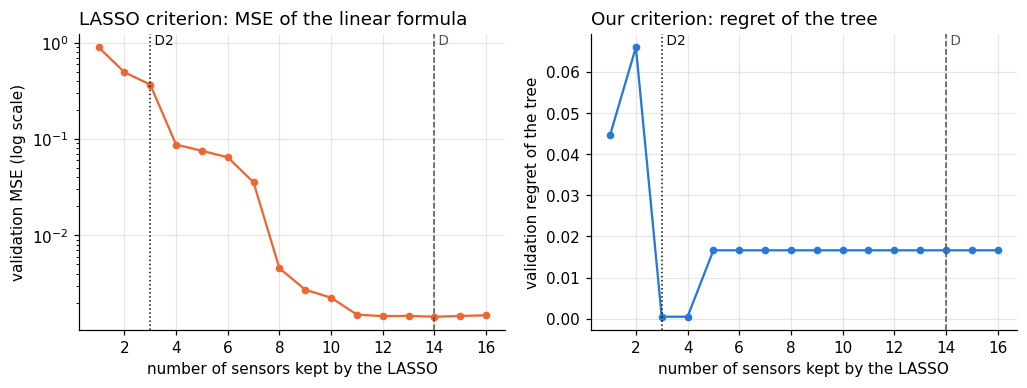

In [4]:
# Left: what the LASSO optimises (MSE of a linear formula). Right: what we care about (regret of the tree)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
ax1.plot(d2_table["n_sensors"], d2_table["lasso_val_MSE"], color=ORANGE, marker="o", ms=4, lw=1.5)
ax1.set_yscale("log")
ax1.set_ylabel("validation MSE (log scale)")
ax1.set_title("LASSO criterion: MSE of the linear formula", loc="left")
ax2.plot(d2_table["n_sensors"], d2_table["val_regret"], color=BLUE, marker="o", ms=4, lw=1.5)
ax2.set_ylabel("validation regret of the tree")
ax2.set_title("Our criterion: regret of the tree", loc="left")
for ax in (ax1, ax2):
    ax.axvline(len(cols_D), color=GREY, ls="--", lw=1)
    ax.axvline(len(cols_D2), color=INK, ls=":", lw=1)
    ax.text(len(cols_D), ax.get_ylim()[1], " D", color=GREY, va="top", fontsize=9)
    ax.text(len(cols_D2), ax.get_ylim()[1], " D2", color=INK, va="top", fontsize=9)
    ax.set_xlabel("number of sensors kept by the LASSO")
plt.show()

- With the regret as criterion, the LASSO path keeps only **3 sensors: S1_Light, S2_Light and S3_Light**, with a validation regret of 0.0005 (against 0.017 for D). With 4 sensors (+ S7_PIR) the regret is the same, and the tie rule keeps 3.
- The figure shows the conflict between the two criteria: the MSE of the linear formula (left) keeps going down until about 11 sensors, while the regret of the tree (right) is lowest with 3 or 4 sensors. From 5 sensors on (when S5_CO2 enters), the regret jumps back to 0.017, the value of A.
- D2 and C reach **exactly the same validation scores**, with 3 sensors each. Two different selection methods agree: the light sensors carry almost all the information in this data. They differ by one sensor only (C has S1_Temp, D2 has S3_Light).

## 11.3 - Candidate E: an L1-penalised logistic regression

The LASSO of candidate D treats the number of people as a **number** (linear regression), and then a tree does the classification. A **logistic regression with an L1 penalty** does both jobs in one model:
- it is a real **classifier** for the 4 headcounts and gives **probabilities**, so we can use our `action` rule directly;
- the L1 penalty (the same idea as the LASSO) puts some sensor coefficients exactly to 0, so it also **selects sensors**.

In scikit-learn the penalty is given by `C = 1/λ`: a **small C means a strong penalty** and few sensors. We use the standardised sensors (`Ztr`, `Zva` from the LASSO part), try 21 values of C, and keep the one with the lowest validation regret (fewest sensors if there is a tie).

In [5]:
from sklearn.linear_model import LogisticRegression

def standardise(X):
    """The 16 raw sensors standardised with the train mean and std (same as for the LASSO)"""
    return (X[features] - mu) / sd

Cs = np.logspace(-3, 2, 21)
e_rows, e_models = [], []
for C in Cs:
    # l1_ratio=1 means a pure L1 (LASSO) penalty (scikit-learn >= 1.8; with an older version write penalty="l1")
    model = LogisticRegression(l1_ratio=1.0, C=C, solver="saga", max_iter=20000, random_state=0).fit(Ztr, ytr)
    kept = [f for f, w in zip(features, np.abs(model.coef_).max(axis=0)) if w > 1e-8]   # kept if one of its 4 class coefficients is not 0
    e_models.append((model, kept))
    e_rows.append({"C": C, "n_sensors": len(kept), **evaluate(model, Zva, yva),
                   "sensors": ", ".join(kept) if len(kept) <= 5 else f"{len(kept)} sensors"})
e_table = pd.DataFrame(e_rows)

e_table["regret_r"] = e_table["regret"].round(10)
j_E = e_table.sort_values(["regret_r", "n_sensors"]).index[0]
e_table = e_table.drop(columns="regret_r")
model_E, cols_E_used = e_models[j_E]
C_E_best = float(Cs[j_E])
print(f"Chosen C for E: {C_E_best:.4f} ->", len(cols_E_used), "sensors with a non-zero coefficient")
e_table.round(4)

Chosen C for E: 1.7783 -> 16 sensors with a non-zero coefficient


,C,n_sensors,accuracy,macro_F1,mean_cost,regret,sensors
0,0.0010,1,0.7577,0.2155,0.8922,0.4114,S1_Light
1,0.0018,1,0.7582,0.2247,0.6580,0.1772,S1_Light
2,0.0032,4,0.8651,0.5112,0.5430,0.0622,"S1_Light, S2_Light, S3_Light, S5_CO2"
3,0.0056,6,0.8850,0.5948,0.5568,0.0760,6 sensors
4,0.0100,6,0.8841,0.5931,0.5986,0.1178,6 sensors
5,0.0178,9,0.9007,0.6777,0.5748,0.0941,9 sensors
6,0.0316,10,0.9321,0.8076,0.5487,0.0679,10 sensors
7,0.0562,12,0.9330,0.8102,0.5477,0.0670,12 sensors
8,0.1000,13,0.9454,0.8458,0.5235,0.0428,13 sensors
9,0.1778,14,0.9758,0.9298,0.5012,0.0204,14 sensors


- E reaches a validation regret of **0.0024**: much better than A, B and D, slightly worse than C and D2.
- But at its best C the penalty is weak, and **all 16 sensors keep a non-zero coefficient**. E is a good model but not a good *selector*: its sparse versions (1 to 6 sensors, C ≤ 0.0056) have a regret between 0.06 and 0.41.
- One advantage of E: its probabilities are real probabilities, not 0 or 1 like most leaves of our trees (see 11.7). So the cost rule of section 5 can really do its job with E.

## 11.4 - All candidates on validation, then on test

We add D2 and E to the dictionary of candidates and redo the validation table of section 9 and the test table of section 10.
**Reminder:** the final choice made in section 9 (candidate C) does not change. D2 and E are only here for the discussion, since they were built after the test.

In [6]:
candidates_plus = dict(candidates)
candidates_plus["D2: tree, LASSO path + regret"] = (tree_D2, cols_D2, params_D2, raw)
candidates_plus["E: L1 logistic regression"] = (model_E, list(features), {"C": round(C_E_best, 4)}, standardise)

def table_on(X, y):
    """Scores of the 2 baselines and of every candidate on the rows X, y"""
    rows = {"Never ventilate (always predict 0)": {"n_sensors": 0, **scores(y, np.zeros_like(y), np.zeros_like(y))},
            "Always ventilate for 3": {"n_sensors": 0, **scores(y, np.full_like(y, 3), np.full_like(y, 3))}}
    for name, (model, cols, params, prep) in candidates_plus.items():
        n = len(cols_E_used) if name.startswith("E") else len(cols)
        rows[name] = {"n_sensors": n, **evaluate(model, prep(X)[cols], y)}
    return pd.DataFrame.from_dict(rows, orient="index")

print("VALIDATION")
display(table_on(Xva, yva).round(4))
print("TEST (D2 and E were built after the test: these numbers are for discussion only)")
display(table_on(Xte, yte).round(4))

VALIDATION


,n_sensors,accuracy,macro_F1,mean_cost,regret
Never ventilate (always predict 0),0,0.7577,0.2155,0.9615,0.4808
Always ventilate for 3,0,0.0618,0.0291,3.0000,2.5192
"A: tree, 16 raw sensors",16,0.9834,0.9450,0.4974,0.0166
"B: tree, 6 aggregated sensors",6,0.9150,0.7587,0.5658,0.0850
"C: tree, forward selection",3,0.9995,0.9990,0.4812,0.0005
"D: tree, LASSO selection",14,0.9834,0.9450,0.4974,0.0166
"D2: tree, LASSO path + regret",3,0.9995,0.9990,0.4812,0.0005
E: L1 logistic regression,16,0.9976,0.9931,0.4831,0.0024


TEST (D2 and E were built after the test: these numbers are for discussion only)


,n_sensors,accuracy,macro_F1,mean_cost,regret
Never ventilate (always predict 0),0,0.9391,0.3229,0.3271,0.1636
Always ventilate for 3,0,0.0417,0.0267,3.0000,2.8364
"A: tree, 16 raw sensors",16,0.9436,0.4357,0.2962,0.1327
"B: tree, 6 aggregated sensors",6,0.9467,0.4950,0.2931,0.1296
"C: tree, forward selection",3,0.9583,0.6321,0.2815,0.1180
"D: tree, LASSO selection",14,0.9436,0.4357,0.2962,0.1327
"D2: tree, LASSO path + regret",3,0.9502,0.5578,0.2896,0.1260
E: L1 logistic regression,16,0.9502,0.5578,0.2896,0.1260


- **Validation:** C and D2 are tied (regret 0.0005, 3 sensors each), then E (0.0024), A = D (0.017) and B (0.085). The rule of section 9 (lowest regret, then fewest sensors) cannot separate C and D2. C stays the final model, since it was chosen and frozen before the test.
- **Test (for discussion only):** C 0.118, D2 = E 0.126, B 0.130, A = D 0.133, never ventilate 0.164. D2 is better than the old D (0.126 vs 0.133) with 3 sensors instead of 14: **changing how λ is chosen is enough to make the LASSO useful.**
- On test, every candidate is only a little better than "never ventilate". Sections 11.5 and 11.6 explain why.

## 11.5 - Where does the test regret come from?

In section 10 we saw that candidate C chose level 0 for 184 rows with 3 people on 10 Jan. We now measure **how much of the test regret** comes from these rows, for every candidate, and we look at what the sensors say during this episode.

In [7]:
episode = (yte == 3) & (final_actions == 0)          # the rows that the final model (C) missed
ts_te = df.loc[df.split == "test", "ts"]
print(f"Episode: {episode.sum()} rows, from {ts_te[episode].min()} to {ts_te[episode].max()}")

share_rows = {}
for name, (model, cols, params, prep) in candidates_plus.items():
    a = action(tree_proba(model, prep(Xte)[cols]))
    extra = LOSS[a, yte] - LOSS[yte, yte]              # extra cost of each row compared to perfect information
    share_rows[name] = {"test_regret": extra.mean(),
                        "regret_without_episode": extra[~episode].sum() / len(yte),
                        "share_from_episode_%": 100 * extra[episode].sum() / extra.sum(),
                        "episode_rows_ventilated": int((a[episode] > 0).sum())}
display(pd.DataFrame(share_rows).T.round(3))

# what do the sensors say during the episode, compared to the training rows with 0 and 3 people?
show = ["S1_Light", "S2_Light", "S3_Light", "S5_CO2", "S5_CO2_Slope", "S1_Sound", "S3_Sound", "S6_PIR", "S7_PIR"]
train_df = df[df.split == "train"]
pd.DataFrame({"train, 0 people": train_df.loc[train_df[TARGET] == 0, show].mean(),
              "train, 3 people": train_df.loc[train_df[TARGET] == 3, show].mean(),
              "test episode (3 people)": Xte.loc[episode, show].mean()}).round(2)

Episode: 184 rows, from 2018-01-10 15:25:48 to 2018-01-10 17:00:15


,test_regret,regret_without_episode,share_from_episode_%,episode_rows_ventilated
"A: tree, 16 raw sensors",0.133,0.018,86.250,0.0
"B: tree, 6 aggregated sensors",0.130,0.015,88.320,0.0
"C: tree, forward selection",0.118,0.004,97.012,0.0
"D: tree, LASSO selection",0.133,0.018,86.250,0.0
"D2: tree, LASSO path + regret",0.126,0.012,90.789,0.0
E: L1 logistic regression,0.126,0.012,90.789,0.0


,"train, 0 people","train, 3 people",test episode (3 people)
S1_Light,3.58,152.96,6.68
S2_Light,4.01,240.47,7.22
S3_Light,18.63,206.74,35.20
S5_CO2,462.44,998.17,532.04
S5_CO2_Slope,-0.62,2.09,2.17
S1_Sound,0.08,0.72,0.35
S3_Sound,0.07,1.13,0.23
S6_PIR,0.00,0.63,0.53
S7_PIR,0.00,0.70,0.67


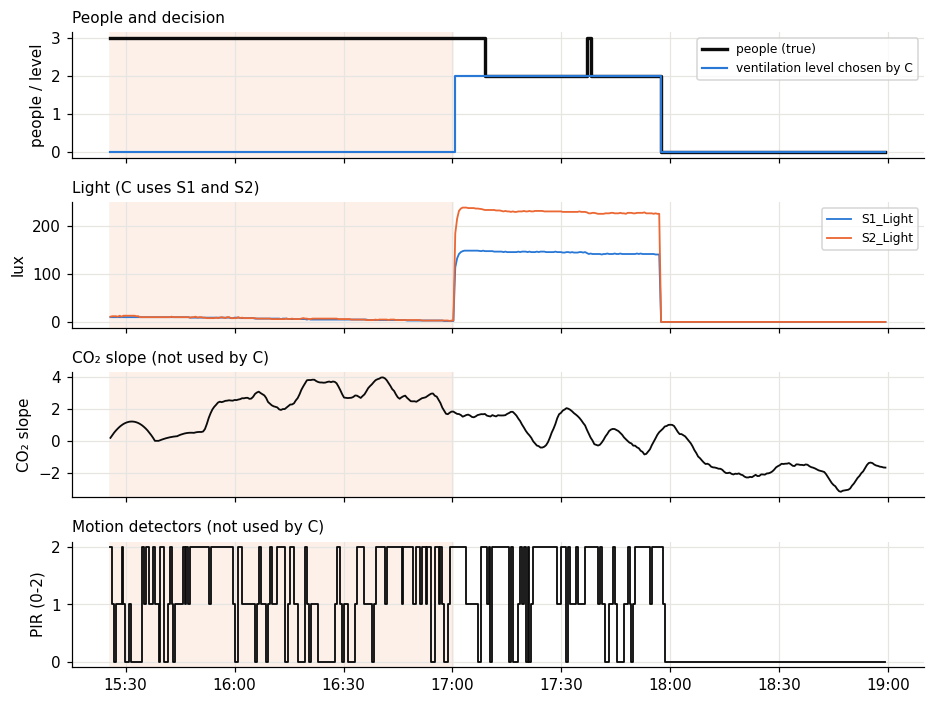

In [8]:
# 10 Jan afternoon: true number of people, level chosen by C, and three sensors. The missed episode is shaded
day = (df.split == "test") & (df.ts >= pd.Timestamp("2018-01-10 15:00")) & (df.ts < pd.Timestamp("2018-01-10 19:00"))
d = df[day]
a_day = final_actions[day[df.split == "test"].to_numpy()]
t0, t1 = ts_te[episode].min(), ts_te[episode].max()

fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"hspace": 0.35})
axes[0].step(d.ts, d[TARGET], where="post", color=INK, lw=2.2, label="people (true)")
axes[0].step(d.ts, a_day, where="post", color=BLUE, lw=1.4, label="ventilation level chosen by C")
axes[0].set_yticks([0, 1, 2, 3]); axes[0].set_ylabel("people / level")
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(d.ts, d.S1_Light, color=BLUE, lw=1.2, label="S1_Light")
axes[1].plot(d.ts, d.S2_Light, color=ORANGE, lw=1.2, label="S2_Light")
axes[1].set_ylabel("lux"); axes[1].legend(loc="upper right", fontsize=8)
axes[2].plot(d.ts, d.S5_CO2_Slope, color=INK, lw=1.2)
axes[2].set_ylabel("CO₂ slope")
axes[3].step(d.ts, d.S6_PIR + d.S7_PIR, where="post", color=INK, lw=1.2)
axes[3].set_yticks([0, 1, 2]); axes[3].set_ylabel("PIR (0-2)")
for ax, title in zip(axes, ["People and decision", "Light (C uses S1 and S2)", "CO₂ slope (not used by C)", "Motion detectors (not used by C)"]):
    ax.axvspan(t0, t1, color="#fdf0e9", zorder=0)
    ax.set_title(title, loc="left", fontsize=10)
axes[3].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
plt.show()

- **Between 86% and 97% of the test regret of every candidate comes from this single episode** (184 rows, about 95 minutes). Without it, the regret of C would be 0.004. No candidate ventilates even one of these rows.
- During the episode, the lights S1 and S2 are almost off (about 7 lux, against 150 to 240 lux with 3 people in training). For a model based on light, the room looks empty.
- But the other sensors clearly see people. The CO₂ slope (2.17) is the same as with 3 people in training (2.09), and the motion detectors fire about as often (S6: 0.53 vs 0.63, S7: 0.67 vs 0.70), while they are almost always 0 in an empty room. The sound is also higher than in an empty room. The CO₂ *level* is still low (532 ppm) only because the session has just started.
- The problem comes from the training data. During the 1.5 days of training, light alone separates the headcounts perfectly, so no model had any reason to use CO₂ or the motion detectors. The validation data has the same property, so **this weakness could not be detected before the test.**

In [9]:
# Two ideas to depend less on light. They were imagined AFTER the test, so they are only for discussion
# 1) a safety rule on top of C: if a motion detector fires, ventilate at least for 1 person
# 2) a tree that uses no light sensor at all, tuned on validation like the others
no_light = [f for f in features if "Light" not in f]
tree_NL, params_NL, _ = tune_tree(Xtr[no_light], Xva[no_light])
print("Tree without light, best settings:", params_NL)

ideas = {}
for part, X, y in (("validation", Xva, yva), ("test", Xte, yte)):
    a_C = action(tree_proba(tree_C, X[cols_C]))
    pir = ((X["S6_PIR"] + X["S7_PIR"]) > 0).to_numpy().astype(int)   # 1 if at least one detector fires
    ideas[part] = {"C (final)": mean_cost(a_C, y) - oracle_cost(y),
                   "C + motion safety rule": mean_cost(np.maximum(a_C, pir), y) - oracle_cost(y),
                   "tree without light": mean_cost(action(tree_proba(tree_NL, X[no_light])), y) - oracle_cost(y)}
print("Regret:")
display(pd.DataFrame(ideas).round(4))

# why does the tree without light fail on test? the "empty room" values of some sensors moved between December and January
print("Mean of some sensors when the room is EMPTY, per part:")
df[df[TARGET] == 0].groupby("split")[["S4_Sound", "S5_CO2_Slope", "S5_CO2"]].mean().reindex(["train", "val", "test"]).round(3)

Tree without light, best settings: {'max_depth': 10, 'min_samples_leaf': 5}
Regret:


,validation,test
C (final),0.0005,0.1180
C + motion safety rule,0.0014,0.0906
tree without light,0.1525,0.8186


Mean of some sensors when the room is EMPTY, per part:


,S4_Sound,S5_CO2_Slope,S5_CO2
split,,,
train,0.061,-0.616,462.442
val,0.063,-0.463,432.313
test,0.094,-0.110,367.711


- The **motion safety rule** lowers the test regret from 0.118 to 0.091, but it makes the validation regret a little worse (0.0005 → 0.0014). If we follow our own protocol (choose on validation), we would **not** have kept it. Now that we know about the lights-off case it looks like a good idea, but that is hindsight.
- The **tree without light** is much worse: 0.15 on validation and 0.82 on test. It predicts people in thousands of empty test rows because the "empty room" values of some sensors changed between December and January: S4_Sound goes from 0.061 to 0.094 V, and the CO₂ slope is close to 0 after days of empty room, instead of negative just after a session. A deep tree that splits on such small differences does not transfer to a new period.
- **Lesson:** with this data, we cannot make a model robust to "people with the lights off", because this situation never appears before the test. The real fix is **more data**: more days, other seasons, sessions with people and the lights off.

## 11.6 - Are the differences on test meaningful?

The test regrets of the candidates are close (0.118 to 0.133). Since the test has people in the room only a few hours, we check how stable these numbers are with a **block bootstrap**: we cut the test into blocks of 1 hour, draw blocks at random with replacement 2000 times, and recompute the regret each time. We use blocks (and not single rows) because rows 30 seconds apart are almost the same.

In [10]:
rng = np.random.default_rng(0)
hour = pd.factorize(ts_te.dt.floor("60min"))[0]                 # block number of each test row
blocks = [np.where(hour == b)[0] for b in range(hour.max() + 1)]

test_actions = {"Never ventilate": np.zeros_like(yte)}
for name, (model, cols, params, prep) in candidates_plus.items():
    test_actions[name] = action(tree_proba(model, prep(Xte)[cols]))
extra = {name: LOSS[a, yte] - LOSS[yte, yte] for name, a in test_actions.items()}

boot = {name: [] for name in test_actions}
for _ in range(2000):
    idx = np.concatenate([blocks[b] for b in rng.integers(0, len(blocks), len(blocks))])
    for name in test_actions:
        boot[name].append(extra[name][idx].mean())
boot = {name: np.array(v) for name, v in boot.items()}

ci = pd.DataFrame({name: {"test_regret": extra[name].mean(),
                          "CI_95_low": np.percentile(boot[name], 2.5),
                          "CI_95_high": np.percentile(boot[name], 97.5),
                          # in how many hours does this candidate pay a different cost than C?
                          "hours_different_from_C": len(set(hour[extra[name] != extra[final_name]]))}
                   for name in test_actions}).T
print(len(blocks), "blocks of 1 hour in the test,", len(set(hour[yte > 0])), "of them with people")
ci.round(3)

44 blocks of 1 hour in the test, 3 of them with people


,test_regret,CI_95_low,CI_95_high,hours_different_from_C
Never ventilate,0.164,0.0,0.371,1.0
"A: tree, 16 raw sensors",0.133,0.0,0.323,1.0
"B: tree, 6 aggregated sensors",0.130,0.0,0.318,1.0
"C: tree, forward selection",0.118,0.0,0.305,0.0
"D: tree, LASSO selection",0.133,0.0,0.323,1.0
"D2: tree, LASSO path + regret",0.126,0.0,0.313,1.0
E: L1 logistic regression,0.126,0.0,0.313,1.0


- Only **3 of the 44 test hours have people in the room**. And every candidate pays exactly the same cost as C in all hours except **one** (column `hours_different_from_C`): all the differences between the candidates on test come from a single hour on 10 Jan.
- The 95% intervals go from 0 to about 0.3 for every candidate, including "never ventilate", and they overlap almost completely.
- **Conclusion:** the test set is too small to rank the candidates. We cannot say that C is better than A on test, or even that it is clearly better than never ventilating. The test mainly shows a weakness that all models share (11.5).

## 11.7 - Does our choice of costs (1 and 2) change the conclusions?

We chose by ourselves that a person without enough air costs 2 and one level of energy costs 1. With a ratio r = C_U / C_E, the rule becomes "ventilate for k people as soon as P(k or more) > 1/r". We redo the validation regret for several ratios, without re-tuning anything.

We also check how often the expected-cost rule really **changes** the decision compared to simply taking the most likely headcount.

In [11]:
models_val = {name: (model, prep(Xva)[cols]) for name, (model, cols, params, prep) in candidates_plus.items()}

sens_rows = {}
for r in [1.25, 1.5, 2, 3, 5, 10]:
    L = loss_matrix(c_e=1.0, c_u=r)
    row = {"threshold 1/r": 1 / r,
           "Never ventilate": mean_cost(np.zeros_like(yva), yva, L) - oracle_cost(yva, L)}
    for name, (model, Xv) in models_val.items():
        row[name.split(":")[0]] = mean_cost(action(tree_proba(model, Xv), L), yva, L) - oracle_cost(yva, L)
    sens_rows[f"r = {r}"] = row
print("Validation regret for each cost ratio r")
display(pd.DataFrame(sens_rows).T.round(4))

# how often does the cost rule choose something else than the most likely headcount?
check = {}
for name, (model, Xv) in models_val.items():
    P = tree_proba(model, Xv)
    check[name] = {"rows with a probability of exactly 1 (%)": 100 * np.mean(P.max(axis=1) == 1),
                   "action != most likely, r = 2 (%)": 100 * np.mean(action(P) != P.argmax(axis=1)),
                   "action != most likely, r = 10 (%)": 100 * np.mean(action(P, loss_matrix(1.0, 10)) != P.argmax(axis=1))}
pd.DataFrame(check).T.round(2)

Validation regret for each cost ratio r


,threshold 1/r,Never ventilate,A,B,C,D,D2,E
r = 1.25,0.8000,0.1202,0.0045,0.0476,0.0005,0.0045,0.0005,0.0005
r = 1.5,0.6667,0.2404,0.0086,0.0601,0.0005,0.0086,0.0005,0.0005
r = 2,0.5000,0.4808,0.0166,0.0850,0.0005,0.0166,0.0005,0.0024
r = 3,0.3333,0.9615,0.0328,0.1349,0.0010,0.0328,0.0005,0.0057
r = 5,0.2000,1.9230,0.0651,0.2347,0.0010,0.0651,0.0005,0.0105
r = 10,0.1000,4.3268,0.1458,0.4841,0.0010,0.1458,0.0005,0.0285


,rows with a probability of exactly 1 (%),"action != most likely, r = 2 (%)","action != most likely, r = 10 (%)"
"A: tree, 16 raw sensors",88.84,0.0,0.00
"B: tree, 6 aggregated sensors",100.00,0.0,0.00
"C: tree, forward selection",90.02,0.0,0.05
"D: tree, LASSO selection",88.84,0.0,0.00
"D2: tree, LASSO path + regret",33.49,0.0,0.00
E: L1 logistic regression,0.00,0.0,2.61


- **The ranking does not depend on our cost choice.** For every ratio from 1.25 to 10, C and D2 stay the best, and every candidate stays far below "never ventilate". Our conclusions do not depend on the 1 and 2 we picked.
- The trees give a probability of **exactly 1** to most rows (89% to 100%, except D2 whose leaves have at least 10 rows). With such probabilities, the expected-cost rule gives the **same answer as "take the most likely headcount"** in 100% of the validation rows at r = 2, and almost always even at r = 10.
- So the decision part of section 5 is correct, but with our trees it never changes a decision. It only becomes useful with real probabilities: E already changes 2.6% of its decisions at r = 10. Bigger leaves (`min_samples_leaf`) or calibrated probabilities would make the cost rule matter for the trees too.